## VAR y CVAR - Parcial 2
#### Simulación de Procesos Financieros
José Armando Melchor Soto | 11/11/2026

---

#### Libraries

In [81]:
import random
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt


random.seed(42)
from warnings import filterwarnings
filterwarnings('ignore')

---

#### Investigación de los activos 


- AAPL – Apple Inc.: Empresa del sector tecnológico dedicada al diseño y comercialización de dispositivos electrónicos, como iPhone, Mac y iPad, además de servicios digitales. Su crecimiento depende de la innovación, el consumo y la expansión de su ecosistema.

- MSFT – Microsoft Corporation: Empresa tecnológica enfocada en software, servicios empresariales y computación en la nube. Sus principales motores de crecimiento son Azure, Microsoft 365 y la inteligencia artificial.

- NVDA – NVIDIA Corporation: Empresa especializada en semiconductores y unidades de procesamiento gráfico (GPU). Su crecimiento está impulsado principalmente por la demanda de infraestructura para inteligencia artificial y centros de datos.

---

#### Parámetros

In [82]:
tickers = ['AAPL', 'MSFT', 'NVDA']
V0 = 100000
M = 10000
T = 1

escenarios = {
    "[1, 0, 0]": np.array([1, 0, 0]),
    "[0.33, 0.33, 0.34]": np.array([0.33, 0.33, 0.34]),
    "[0.2, 0.2, 0.6]": np.array([0.2, 0.2, 0.6])
}

Aquí se definenn los parámetros de los 3 activos, $100,000 para invertir y 10,000 simulaciones , con T = 1.

---

#### Functions

In [83]:
def obtener_datos(tickers):
    """Descarga los precios históricos y calcula los rendimientos y parámetros.

    Args:
        tickers: Lista de símbolos de los activos.

    Returns:
        datos: Precios históricos de cierre.
        rend: Rendimientos logarítmicos diarios.
        mu: Rendimiento promedio anualizado.
        sigma: Volatilidad anualizada.
        R: Matriz de correlaciones.
    """
    datos = yf.download(tickers, period='1y', progress=False)['Close']
    datos = datos[tickers]
    datos = datos.dropna()

    rend = np.log(datos / datos.shift(1)).dropna()
    mu = rend.mean().values * 252
    sigma = rend.std().values * np.sqrt(252)
    R = rend.corr()

    return datos, rend, mu, sigma, R


def simular_shocks(R, M):
    """Genera variables normales estándar correlacionadas mediante Cholesky.

    Args:
        R: Matriz de correlaciones de los activos.
        M: Número de simulaciones.

    Returns:
        ZT: Matriz de shocks correlacionados.
    """
    L = np.linalg.cholesky(R.values)
    np.random.seed(0)
    epsilon = np.random.normal(0, 1, [3, M])
    Z = L @ epsilon
    ZT = Z.T

    return ZT


def simular_portafolio(datos, mu, sigma, ZT, V0, T, w):
    """Calcula los valores simulados del portafolio y sus ganancias o pérdidas.

    Args:
        datos: Precios históricos de los activos.
        mu: Rendimiento promedio anualizado.
        sigma: Volatilidad anualizada.
        ZT: Shocks normales correlacionados.
        V0: Valor inicial del portafolio.
        T: Horizonte de inversión en años.
        w: Pesos de inversión en cada activo.

    Returns:
        VT: Valores simulados del portafolio al tiempo T.
        ganancia: Ganancia o pérdida de cada simulación.
        ganancias: Simulaciones con ganancia positiva.
        perdidas: Simulaciones con pérdida.
    """
    S0 = datos.iloc[-1].values
    ST = S0 * np.exp((mu - sigma**2 / 2) * T + sigma * np.sqrt(T) * ZT)
    N = w * V0 / S0
    VT = np.sum(N * ST, axis=1)
    ganancia = VT - V0
    ganancias = ganancia[ganancia > 0]
    perdidas = ganancia[ganancia < 0]

    return VT, ganancia, ganancias, perdidas


def VAR(ganancia):
    """Calcula el Valor en Riesgo (VaR) al 95% de confianza.

    Args:
        ganancia: Ganancia o pérdida de cada simulación.

    Returns:
        VaR: Valor en Riesgo al 95% de confianza.
    """
    VaR = np.percentile(ganancia, 5)
    return VaR

def CVAR(ganancia):
    """Calcula el Valor en Riesgo Condicional (CVaR) al 95% de confianza.

    Args:
        ganancia: Ganancia o pérdida de cada simulación.

    Returns:
        CVaR: Valor en Riesgo Condicional al 95% de confianza.
    """
    VaR = VAR(ganancia)
    CVaR = ganancia[ganancia <= VaR].mean()
    return CVaR

def graficar_resultados(VT, ganancia, V0, T, nombre):
    """Grafica en una misma figura la distribución del valor del portafolio (izquierda)
    y sus ganancias o pérdidas (derecha), con media, cuartiles, VaR y CVaR.

    Args:
        VT: Valores simulados del portafolio al tiempo T.
        ganancia: Ganancia o pérdida de cada simulación.
        V0: Valor inicial del portafolio.
        T: Horizonte de inversión en años.
        nombre: Esquema de inversión que se está graficando.
    """
    VaR = VAR(ganancia)
    CVaR = CVAR(ganancia)

    media = VT.mean()
    Q1, Q2, Q3 = np.percentile(VT, [25, 50, 75])

    media_g = ganancia.mean()
    Q1_g, Q2_g, Q3_g = np.percentile(ganancia, [25, 50, 75])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

    # Izquierda: distribución del valor del portafolio
    ax1.hist(VT, bins=100, color='#4472A8', alpha=0.75, edgecolor='white', linewidth=0.3)

    ax1.axvline(V0, color='#343A40', linestyle='--', linewidth=2, label='V0')
    ax1.axvline(media, color='#F4A261', linestyle='-', linewidth=2, label='Media')
    ax1.axvline(Q1, color='#E76F51', linestyle=':', linewidth=2, label='Q1')
    ax1.axvline(Q2, color='#2A9D8F', linestyle=':', linewidth=2, label='Q2')
    ax1.axvline(Q3, color='#457B9D', linestyle=':', linewidth=2, label='Q3')
    ax1.axvline(V0 + VaR, color='#9B5DE5', linestyle='-.', linewidth=2.2, label=f'VaR 95%: {VaR:,.0f}')
    ax1.axvline(V0 + CVaR, color='#D62828', linestyle='-.', linewidth=2.2, label=f'CVaR 95%: {CVaR:,.0f}')

    ax1.set_xlabel('VT')
    ax1.set_ylabel('Frecuencia')
    ax1.set_title(f'Distribución del valor del portafolio {nombre} en T = {T}')
    ax1.legend(frameon=False)
    ax1.grid(axis='y', alpha=0.2, linestyle='--')

    # Derecha: distribución de ganancias y pérdidas
    bins = np.linspace(ganancia.min(), ganancia.max(), 100)

    ax2.hist(ganancia[ganancia < 0], bins=bins, color='#E76F51',
             alpha=0.75, label='Pérdida', edgecolor='white', linewidth=0.3)

    ax2.hist(ganancia[ganancia >= 0], bins=bins, color='#2A9D8F',
             alpha=0.75, label='Ganancia', edgecolor='white', linewidth=0.3)

    ax2.axvline(0, color='#343A40', linestyle='--', linewidth=2, label='Equilibrio')
    ax2.axvline(media_g, color='#F4A261', linestyle='-', linewidth=2, label='Media')
    ax2.axvline(Q1_g, color='#E76F51', linestyle=':', linewidth=2, label='Q1')
    ax2.axvline(Q2_g, color='#2A9D8F', linestyle=':', linewidth=2, label='Q2')
    ax2.axvline(Q3_g, color='#457B9D', linestyle=':', linewidth=2, label='Q3')
    ax2.axvline(VaR, color='#9B5DE5', linestyle='-.', linewidth=2.2, label=f'VaR 95%: {VaR:,.0f}')
    ax2.axvline(CVaR, color='#D62828', linestyle='-.', linewidth=2.2, label=f'CVaR 95%: {CVaR:,.0f}')

    ax2.set_xlabel('VT - V0')
    ax2.set_ylabel('Frecuencia')
    ax2.set_title(f'Ganancia o pérdida del portafolio {nombre} en T = {T}')
    ax2.legend(frameon=False)
    ax2.grid(axis='y', alpha=0.2, linestyle='--')

    plt.tight_layout()
    plt.show()


def tabla_riesgo(portafolio):
    """Resume media, cuartiles, VaR y CVaR de cada esquema de inversión.

    Args:
        portafolio: Diccionario con la ganancia o pérdida de cada esquema.

    Returns:
        tabla: DataFrame con las medidas de riesgo de cada esquema.
    """
    tabla = pd.DataFrame({
        nombre: {
            "Media": portafolio[nombre].mean(),
            "Q1": np.percentile(portafolio[nombre], 25),
            "Q2": np.percentile(portafolio[nombre], 50),
            "Q3": np.percentile(portafolio[nombre], 75),
            "VaR 95%": VAR(portafolio[nombre]),
            "CVaR 95%": CVAR(portafolio[nombre]),
            "P(pérdida)": np.mean(portafolio[nombre] < 0)
        }
        for nombre in portafolio
    }).T

    return tabla


---

#### Simulación

In [84]:
datos, rend, mu, sigma, R = obtener_datos(tickers)
print(pd.DataFrame({'mu': mu, 'sigma': sigma}, index=tickers))

ZT = simular_shocks(R, M)

VT = {}
ganancia = {}

for nombre, w in escenarios.items():
    VT[nombre], ganancia[nombre], _, _ = simular_portafolio(datos, mu, sigma, ZT, V0, T, w)

            mu     sigma
AAPL  0.267540  0.250392
MSFT  0.027770  0.336959
NVDA -0.107787  0.386673


AAPL presenta el mejor perfil riesgo-rendimiento, con el mayor rendimiento esperado (26.75%) y la menor volatilidad (25.04%). MSFT ofrece un rendimiento bajo (2.78%) con mayor riesgo, mientras que NVDA resulta menos atractivo, al tener un rendimiento esperado negativo (-10.78%) y la volatilidad más alta (38.67%).

---

In [85]:
tabla_riesgo(ganancia).round(4)

,Media,Q1,Q2,Q3,VaR 95%,CVaR 95%,P(pérdida)
"[1, 0, 0]",29980.1581,6555.4366,25786.2192,48879.6409,-15848.9091,-23575.1628,0.1748
"[0.33, 0.33, 0.34]",7351.5180,-8905.9664,5029.6246,20434.8424,-24991.3698,-30974.9845,0.4053
"[0.2, 0.2, 0.6]",357.6056,-17702.5214,-3197.9870,14113.6861,-33981.9190,-40010.4256,0.5556


---

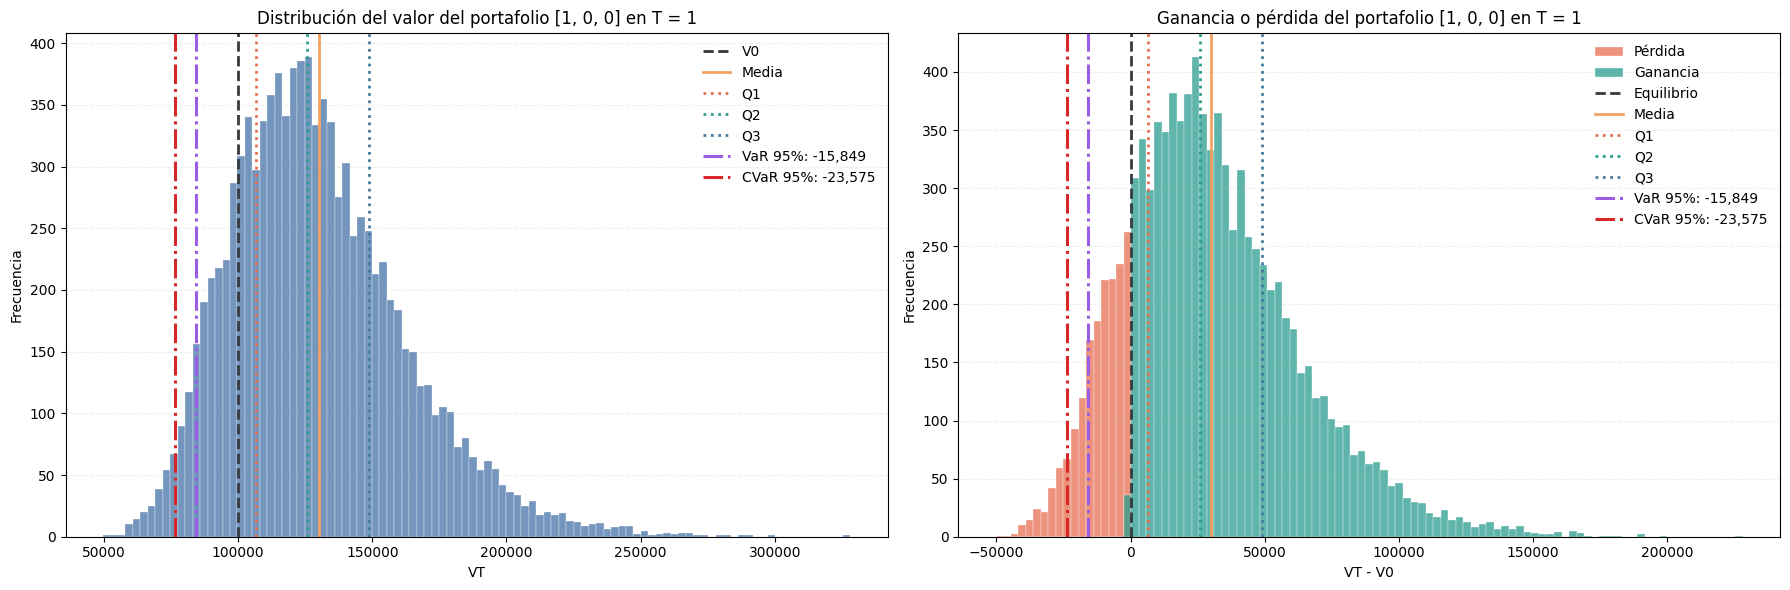

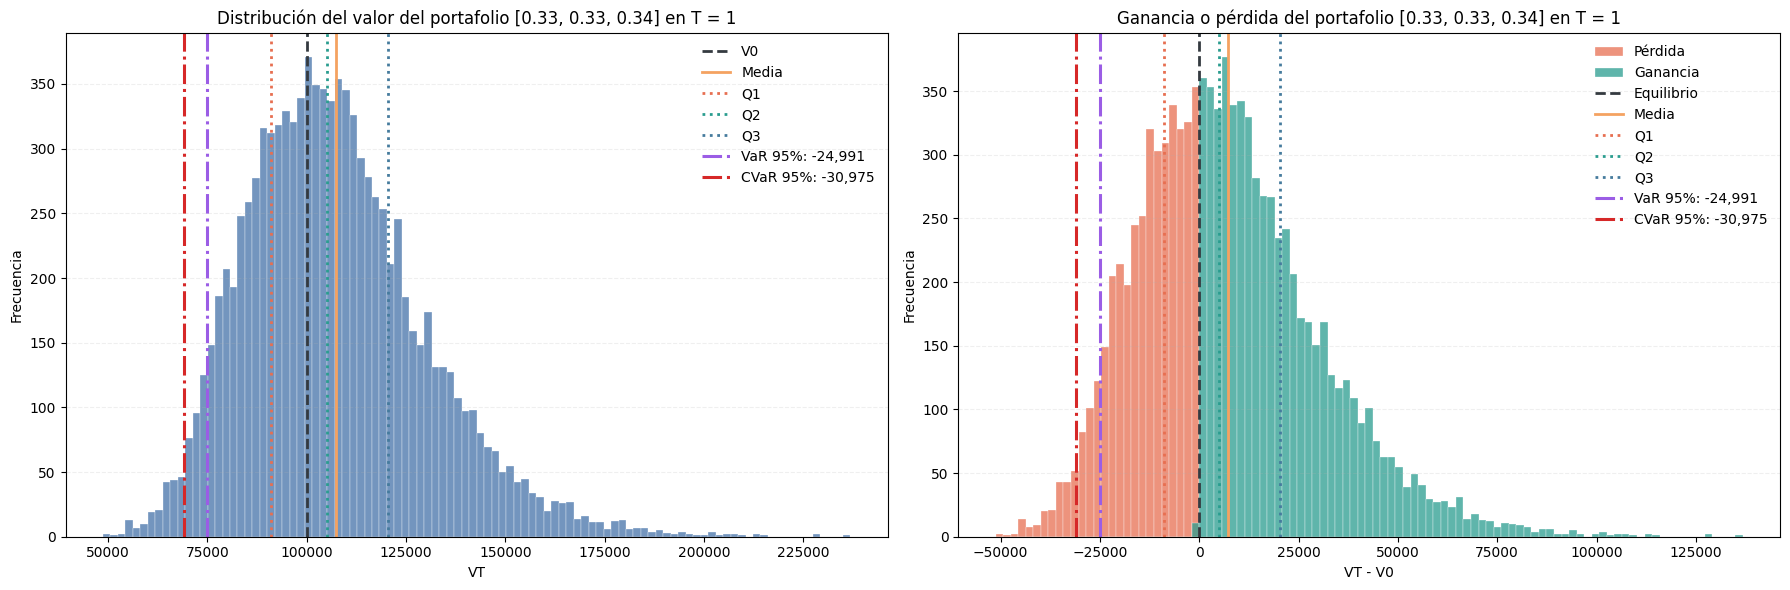

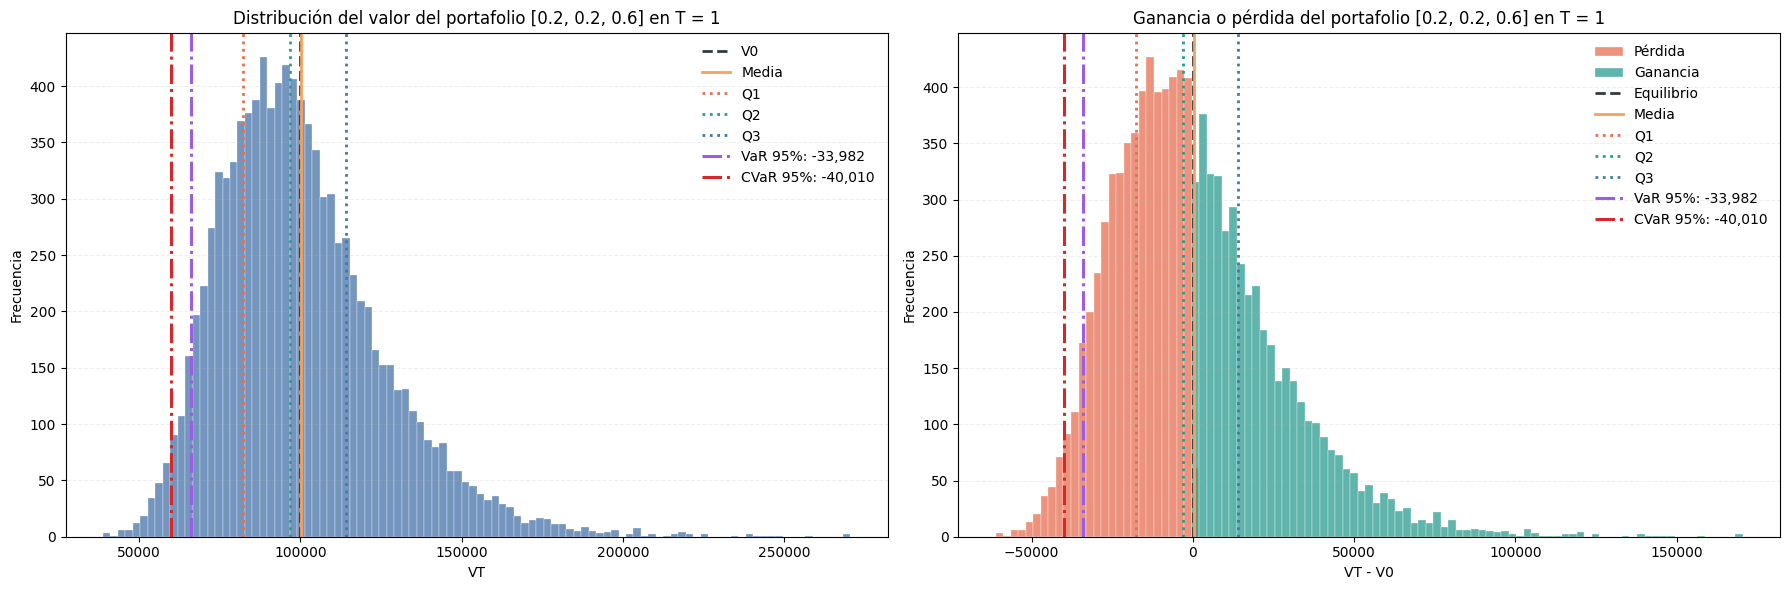

In [86]:
for nombre in escenarios:
    graficar_resultados(VT[nombre], ganancia[nombre], V0, T, nombre)

La simulación muestra que invertir todo en AAPL [1, 0, 0] fue la mejor opción, con una ganancia promedio de +$29,980 y solo 17.5% de escenarios con pérdidas. Por otro lado, al aumentar el peso de NVDA, las ganancias disminuyen y el riesgo aumenta, llegando a 55.6% de escenarios con pérdidas en [0.2, 0.2, 0.6].

Esto coincide con los rendimientos y volatilidades estimados, ya que NVDA presentó el menor rendimiento esperado y la mayor volatilidad, mientras que AAPL tuvo el mejor comportamiento. algo que podría mencionar es que parece una grafica con un comportamiento de una distribución normal y que en general tiende a haber más perdidas que ganancia . 

En conclusión, AAPL fue el activo más favorable dentro de las simulaciones, mientras que aumentar la exposición a NVDA generó resultados menos favorables.

---